# 4. Real recordings

`timescales.data` contains the median power spectrum and median
autocorrelation of eight public recordings: fMRI, MEG, EEG, ECoG, LFP and
spike counts, from four species.  Sampling rates range from 0.5 to 250 Hz.
The analysis band differs by modality and is listed below.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from timescales import ARACF, ARPSD
from timescales.data import DATASETS, LABELS, load_acf, load_spectrum

plt.rcParams.update({'font.size': 10})

for key in DATASETS:
    freqs, powers, fs = load_spectrum(key)
    print(f'{LABELS[key]:<40} fs = {fs:>6.1f} Hz   '
          f'{freqs[0]:g}-{freqs[-1]:g} Hz')

Human fMRI (precuneus, rest)             fs =    0.5 Hz   0.015625-0.234375 Hz
Human EEG (posterior, eyes closed)       fs =  250.0 Hz   1-100 Hz
Human MEG (sensorimotor)                 fs =  250.0 Hz   1-95 Hz
Human ECoG (motor cortex)                fs =  250.0 Hz   1-100 Hz
Macaque ECoG (visual cortex)             fs =  250.0 Hz   1-100 Hz
Mouse LFP (visual cortex)                fs =  250.0 Hz   1.25-99.9998 Hz
Mouse spike counts (visual cortex)       fs =   20.0 Hz   0.05-2 Hz
Rat LFP (hippocampus)                    fs =  250.0 Hz   1-100 Hz


## One configuration applied to all recordings

One configuration fits all eight recordings: `fs` and the data are the only
inputs that differ.  It is the configuration used for the figures in the
paper, and it has three parts.

`order` is a log-spaced grid ending at 20.  BIC over AR order is not
unimodal, so the grid is searched in full rather than stopped early, and it is
coarse because BIC is smooth in `p`: a log-spaced grid finds the same minimum
as an exhaustive search at a fraction of the cost.

`loss='soft_l1'` with `f_scale=0.15` fits the spectrum robustly.  A rhythm is
an outlier in the frequency domain, occupying a handful of bins out of a
thousand, so down-weighting large residuals leaves the aperiodic fit intact.

`require_relaxation=True` forces the model to contain at least one real pole.
A model whose poles are all complex has no decay time to report, which fails
as a measurement of a timescale even when it describes the data well.

Two things happen to the spectrum before it is fit.

The bins are thinned to uniform spacing in *log* frequency.  On a linear grid
80% of the bins of a 1-100 Hz band lie above 50 Hz, so a least-squares fit in
log power is overwhelmingly a fit to the high-frequency tail.

The order grid is then capped at one AR coefficient per five fitted bins.
Order selection counts fitted points as independent observations, and a short
record cannot support twenty poles: the fMRI spectrum has 29 bins, and without
the cap BIC buys ten of them.

In [2]:
import warnings

ORDER_GRID = (1, 2, 3, 4, 5, 6, 8, 10, 13, 16, 20)
SETTINGS = dict(loss='soft_l1', f_scale=0.15, require_relaxation=True)


def fit_points(freqs, powers):
    """Thin a spectrum to uniform spacing in log frequency."""
    n = len(freqs)
    edges = np.logspace(np.log10(freqs[0]), np.log10(freqs[-1]), n)
    idx = np.unique(np.clip(np.searchsorted(freqs, edges), 0, n - 1))
    return freqs[idx], powers[idx]


def orders_for(n_points):
    """One AR coefficient per five fitted bins, at most 20."""
    return [p for p in ORDER_GRID if p <= int(np.clip(n_points // 5, 2, 20))]


results, fitted = {}, {}

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    for key in DATASETS:
        freqs, powers, fs = load_spectrum(key)
        f_fit, p_fit = fit_points(freqs, powers)
        ar = ARPSD(order=orders_for(len(f_fit)), fs=fs, **SETTINGS)
        ar.fit(f_fit, p_fit)
        ar.decompose(freqs=f_fit)
        results[key], fitted[key] = ar, (f_fit, p_fit)

print(f'{"recording":<38}{"p":>4}{"R^2":>8}{"tau":>11}{"modes":>7}{"floor":>8}')
for key, ar in results.items():
    freqs, _ = fitted[key]
    tau = f'{ar.tau * 1e3:.1f} ms' if ar.tau < 1 else f'{ar.tau:.2f} s'
    n_res = len(ar.modes.resolvable((freqs[0], freqs[-1])))
    floor = ar.modes.noise_floor(freqs)
    lvl = '--' if floor is None else f'{floor["relative"]:.2f}'
    print(f'{LABELS[key]:<38}{ar.order_:4d}{ar.rsq:8.3f}{tau:>11}'
          f'{n_res:7d}{lvl:>8}')

recording                                p     R^2        tau  modes   floor
Human fMRI (precuneus, rest)             2   0.982     3.43 s      1    0.31
Human EEG (posterior, eyes closed)      20   0.992    45.9 ms      9    0.84
Human MEG (sensorimotor)                20   0.995    32.6 ms      9    0.79
Human ECoG (motor cortex)               16   0.993    19.7 ms      7    1.49
Macaque ECoG (visual cortex)            13   0.998    23.4 ms      6      --
Mouse LFP (visual cortex)               20   0.988    71.3 ms      8    1.16
Mouse spike counts (visual cortex)      10   0.936     1.02 s      4    0.08
Rat LFP (hippocampus)                   20   0.981    65.7 ms     10      --


Estimated timescales range from tens of milliseconds in electrophysiology to
seconds in BOLD.

`modes` counts the poles the analysis band can measure, which is fewer than
the model order: `resolvable` drops a mode when the frequency it shapes the
spectrum at falls outside the fitted band, because nothing in the data
constrained it there.

`floor` is the noise floor, where the fit has one, as a fraction of the fitted
power at the top of the band. An all-pole model has no additive term, so it
represents a flat floor with a negative real pole, whose factor rises with
frequency. That pole has a level rather than a timescale and is never reported
as a mode. A dash means the spectrum did not reach a floor inside the band.

## Goodness of fit by band

A spectrum sampled on a linear frequency grid puts most of its points in the
top decade, so the overall $R^2$ is dominated by the fastest frequencies.
`error_by_band` reports the median absolute error in each quarter of the log
frequency range, in log10 power: 0.05 dex is a 12% error and 0.30 dex is a
factor of two.

In [3]:
print(f'{"recording":<34}{"overall":>9}   median |error| per band (dex)')
for key, ar in results.items():
    edges, err = ar.error_by_band(4)
    print(f'{LABELS[key][:32]:<34}{ar.rsq:9.3f}   {np.round(err, 3)}')
print(f'\nbands (Hz), rat LFP: {np.round(results["rat_hc3_ca1_ca3"].error_by_band(4)[0], 2)}')

recording                           overall   median |error| per band (dex)
Human fMRI (precuneus, rest)          0.982   [0.012 0.027 0.03  0.03 ]
Human EEG (posterior, eyes close      0.992   [0.053 0.07  0.062 0.028]
Human MEG (sensorimotor)              0.995   [0.13  0.067 0.022 0.018]
Human ECoG (motor cortex)             0.993   [0.067 0.038 0.023 0.033]
Macaque ECoG (visual cortex)          0.998   [0.057 0.042 0.019 0.02 ]
Mouse LFP (visual cortex)             0.988   [0.149 0.099 0.023 0.017]
Mouse spike counts (visual corte      0.936   [0.022 0.055 0.055 0.036]
Rat LFP (hippocampus)                 0.981   [0.043 0.108 0.1   0.041]

bands (Hz), rat LFP: [  1.     3.16  10.    31.62 100.  ]


## AR(1) compared with AR(p)

Each recording is also fit at order 1, with the same loss, so that order is
the only difference between the two fits.

In [4]:
print(f'{"recording":<40}{"AR(1) R^2":>11}{"AR(p) R^2":>11}{"p":>4}')
for key, ar in results.items():
    freqs, powers, fs = load_spectrum(key)
    one = ARPSD(order=1, fs=fs, loss='soft_l1', f_scale=0.15).fit(freqs, powers)
    print(f'{LABELS[key]:<40}{one.rsq:11.3f}{ar.rsq:11.3f}{ar.order_:4d}')

recording                                 AR(1) R^2  AR(p) R^2   p
Human fMRI (precuneus, rest)                  0.969      0.982   2
Human EEG (posterior, eyes closed)            0.924      0.992  20
Human MEG (sensorimotor)                      0.905      0.995  20
Human ECoG (motor cortex)                     0.648      0.993  16
Macaque ECoG (visual cortex)                  0.907      0.998  13
Mouse LFP (visual cortex)                     0.882      0.988  20
Mouse spike counts (visual cortex)            0.694      0.936  10
Rat LFP (hippocampus)                         0.963      0.981  20


Every recording selects an order above 1, and $R^2$ increases in every case.
The increase is largest for the recordings with a narrowband peak.

## Fitted spectra

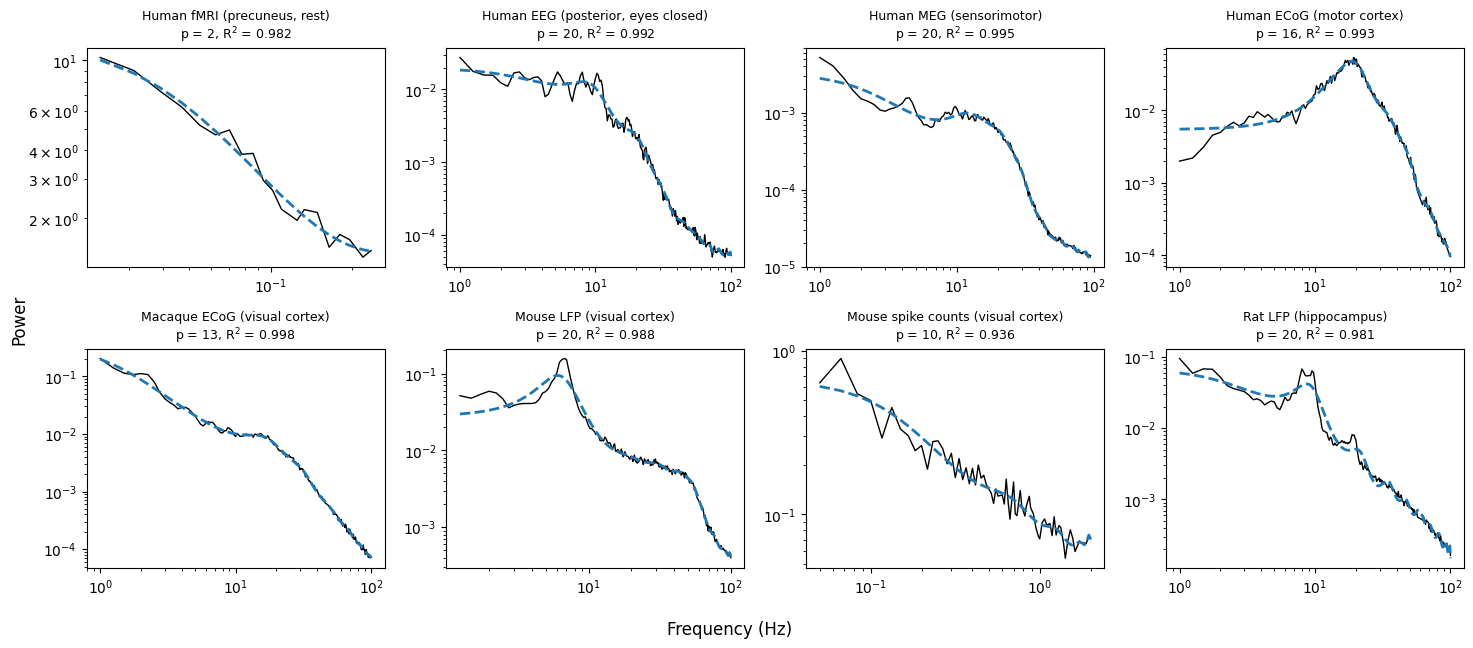

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, (key, ar) in zip(axes.ravel(), results.items()):
    ar.plot(ax=ax, title=None)
    ax.set_title(f'{LABELS[key]}\np = {ar.order_}, R$^2$ = {ar.rsq:.3f}',
                 fontsize=9)
    ax.legend().remove()
    ax.set(xlabel='', ylabel='')
fig.supxlabel('Frequency (Hz)')
fig.supylabel('Power')
fig.tight_layout();

## Which modes to report

An order-20 fit has twenty poles, and most of them are not worth quoting.  Two
filters narrow them down, and they are the ones the paper's figures use.

`modes.resolvable(band)` keeps a mode only if the frequency at which it shapes
the spectrum lies inside the fitted band: a relaxation's knee, an
oscillation's own frequency, $f_s/2$ for a noise floor.  Outside the band
nothing constrained it, so its timescale is an extrapolation.

Of those, report the ones that carry variance.  The mode factors *multiply* in
the spectrum, so no factor has a share of it -- a factor can look prominent and
contribute nothing, because the others fall through the same frequencies.  The
partial fractions *add*: they sum to the model spectrum, their transforms sum
to the model autocorrelation, and each one's value at lag zero is that mode's
share of the variance.  That share is the one quantity that is a share in both
domains, so it selects and ranks the modes for the spectrum and the
autocorrelation alike.

It is also, directly, the size of the curve a mode draws.  A mode holding 0.2%
of the variance contributes an autocorrelation component of amplitude 0.002,
which cannot be told from zero.  `dominant_modes` drops anything below 1%.

In [6]:
from timescales.decomposition.select import dominant_modes, variance_shares

key = 'human_lemon_alpha'
ar = results[key]
modes = ar.modes
freqs, _ = fitted[key]

resolvable = modes.resolvable((freqs[0], freqs[-1]))

# each mode's additive autocorrelation component, normalised so the
# components sum to the model autocorrelation
comps = modes.acf_components(250)
comps = comps / comps[:, 0].sum()
index = {id(m): j for j, m in enumerate(modes.modes)}
shares = variance_shares(resolvable,
                         np.array([comps[index[id(m)]] for m in resolvable]))
reported = dominant_modes(resolvable, shares)

print(f'{LABELS[key]}, order {ar.order_}')
print(f'{len(modes.modes)} poles -> {len(resolvable)} resolvable '
      f'-> {len(reported)} reported\n')
print(f'{"kind":<12}{"tau (ms)":>10}{"freq (Hz)":>11}{"cycles":>9}{"variance":>10}')
for m, share in reported:
    print(f'{m.kind:<12}{m.tau * 1e3:10.1f}{m.freq:11.1f}'
          f'{m.n_cycles:9.2f}{100 * share:9.1f}%')
print(f'\ntogether they hold {100 * sum(s for _, s in reported):.0f}% '
      f'of the variance')

Human EEG (posterior, eyes closed), order 20
11 poles -> 9 resolvable -> 4 reported

kind          tau (ms)  freq (Hz)   cycles  variance
oscillatory       45.9        9.1     0.42     46.7%
relaxation        46.7        0.0     0.00     38.5%
oscillatory       32.1       20.1     0.65     10.0%
oscillatory       22.7       31.0     0.70      1.6%

together they hold 97% of the variance


The `cycles` column is $f\tau$, the number of periods completed before the
envelope decays: modes below 1 are broad spectral features and modes above 1
are rhythms.  It decides which mode `ar.tau` reports, not which modes are
drawn.

/home/rph/timescale-methods/timescales/ar/base.py:196: RuntimeWarning: ARACF: the leading mode rings 0.81 cycles, close to the f*tau = 1 cut that separates a relaxation from a rhythm, so `tau` is decided by a near tie. A small change in order or band can move it by a large factor. Inspect `modes` and consider `tau_dominant`.
  return self.modes if self.modes is not None else self.decompose()


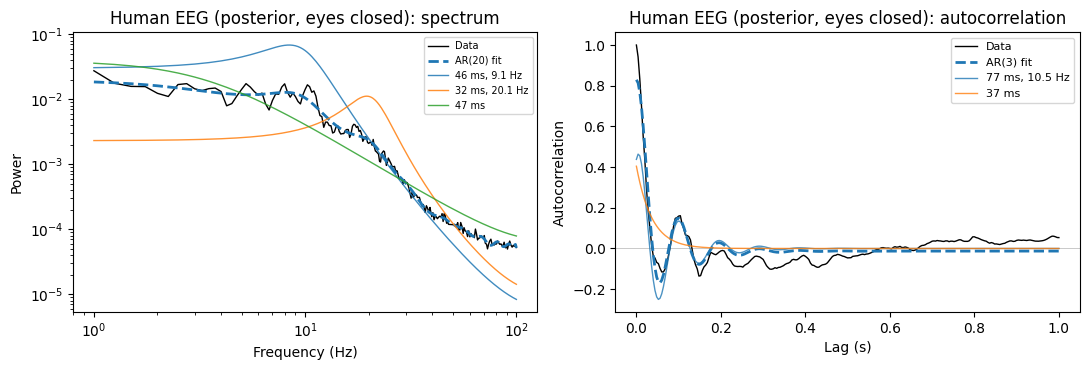

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ar.plot(ax=axes[0], plot_modes=3, title=f'{LABELS[key]}: spectrum')
axes[0].legend(fontsize=7)

lags, corrs, fs = load_acf(key)
acf_fit = ARACF(order=ORDER_GRID, fs=fs, require_relaxation=True).fit(lags, corrs)
acf_fit.plot(ax=axes[1], plot_modes=3, title=f'{LABELS[key]}: autocorrelation')
fig.tight_layout();

## Agreement between domains

Both estimators fit the same coefficients.  The ratio below is the larger
estimate divided by the smaller.

`tau` keeps modes that ring less than one cycle and discards the rest, and the
cut is sharp.  A fit whose leading mode lands near one cycle sets
`tau_near_boundary_` and warns, because a small change in order or band can
then move `tau` by a large factor without the fit getting any worse.  The
`edge` column below marks those.

In [8]:
print(f'{"recording":<40}{"PSD tau":>12}{"ACF tau":>12}{"ratio":>8}{"edge":>7}')
for key in DATASETS:
    freqs, powers, fs = load_spectrum(key)
    lags, corrs, _ = load_acf(key)
    with warnings.catch_warnings(record=True):     # reported in the last column
        warnings.simplefilter('always')
        acf = ARACF(order=ORDER_GRID, fs=fs, require_relaxation=True).fit(lags, corrs)
        a, b = results[key].tau, acf.tau
    ratio = max(a, b) / min(a, b) if np.isfinite(a) and np.isfinite(b) else np.nan
    edge = 'ACF' if acf.tau_near_boundary_ else ''
    edge = ('PSD+' + edge) if results[key].tau_near_boundary_ else edge
    print(f'{LABELS[key]:<40}{a * 1e3:10.1f} m{b * 1e3:10.1f} m{ratio:8.1f}{edge or "-":>7}')

recording                                    PSD tau     ACF tau   ratio   edge
Human fMRI (precuneus, rest)                3430.5 m    4924.4 m     1.4      -
Human EEG (posterior, eyes closed)            45.9 m      77.1 m     1.7    ACF
Human MEG (sensorimotor)                      32.6 m      27.8 m     1.2      -
Human ECoG (motor cortex)                     19.7 m      25.5 m     1.3      -
Macaque ECoG (visual cortex)                  23.4 m      43.2 m     1.8      -
Mouse LFP (visual cortex)                     71.3 m      38.9 m     1.8    ACF
Mouse spike counts (visual cortex)          1015.8 m     600.8 m     1.7      -
Rat LFP (hippocampus)                         65.7 m      45.4 m     1.4    ACF


Six of the eight recordings agree within a factor of two across domains.

The lag-domain fits marked `ACF` sit on the one-cycle boundary.  Their
reported timescale should not be quoted without looking at `modes`: the
spectral fits of the same recordings do not sit there, which is why the two
domains disagree most on exactly those recordings.

## Summary

The interface is three calls:

```python
ar = ARPSD(order=ORDER_GRID, fs=fs, **SETTINGS)   # or ARACF, or order=1
ar.fit(freqs, powers)                   # or (lags, corrs)
ar.decompose()
```

`ar.tau`, `ar.taus`, `ar.freqs_hz`, `ar.rsq` and `ar.plot()` report the
result.